# Predicción de churn — Telco Customer Churn
**Machine Learning II · Ruta A (supervisada) · Universidad Externado**

Notebook de desarrollo en Google Colab. Cubre: exploración del dataset y justificación de variables,
ejecución de `train.py`, lectura de resultados y prueba de la app Streamlit con un túnel temporal.

> El notebook es para experimentar y explicar. El procedimiento reproducible está en `train.py`.

## 0. Preparar el entorno
En Colab, ejecute esta celda. Si subió `ml_streamlit_project.zip` al panel de archivos, lo descomprime; si no, clona el repositorio de GitHub. Si Colab pide reiniciar la sesión tras instalar, reinicie y vuelva a ejecutar esta celda.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/ml_streamlit_project").exists():
        if Path("/content/ml_streamlit_project.zip").exists():
            # Opción A: zip subido al panel de archivos
            subprocess.run(["unzip", "-q", "/content/ml_streamlit_project.zip", "-d", "/content"], check=True)
        else:
            # Opción B: clonar el repositorio de GitHub
            subprocess.run(["git", "clone", "-q", "https://github.com/Gatitomalo1234/churn-streamlit-gcp.git",
                            "/content/ml_streamlit_project"], check=True)
    os.chdir("/content/ml_streamlit_project")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif Path.cwd().name == "notebooks":
    os.chdir("..")
print("Directorio de trabajo:", Path.cwd())

Directorio de trabajo: /home/claude/ml_streamlit_project


## 1. Revisión mínima del dataset (sección 6 de la guía)

In [2]:
import pandas as pd
df = pd.read_csv("data/telco_churn.csv")
print(df.shape, "| duplicados:", df.duplicated().sum())
df.head()

(7043, 21) | duplicados: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
display(df.dtypes)
display(df.describe(include="all").T)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Una fila = un cliente** de una compañía de telecomunicaciones. **Objetivo:** `Churn` (si el cliente canceló el servicio).

## 2. Datos faltantes y el caso de `TotalCharges`

In [4]:
tc = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
print("Nulos tras convertir a número:", tc.isna().sum())
print("tenure de esos clientes:", df.loc[tc.isna(), "tenure"].unique())
print("Corr(TotalCharges, tenure*MonthlyCharges):", round(tc.corr(df["tenure"] * df["MonthlyCharges"]), 4))

Nulos tras convertir a número: 11
tenure de esos clientes: [0]
Corr(TotalCharges, tenure*MonthlyCharges): 0.9996


`TotalCharges` viene como texto, sus vacíos son clientes nuevos (`tenure = 0`) y es prácticamente
`tenure × MonthlyCharges`. Es **redundante**: se excluye y así la app no pide un dato deducible.

## 3. Variable objetivo y relaciones clave

In [5]:
print(df["Churn"].value_counts(normalize=True).round(3))

def tasa_churn(col):
    return df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)

for col in ["gender", "Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen"]:
    print(f"\n{tasa_churn(col)}")
print("\n", df.groupby(pd.cut(df["tenure"], [-1, 12, 24, 48, 72]))["Churn"]
      .apply(lambda s: (s == "Yes").mean()).round(3))

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

gender
Female    0.269
Male      0.262
Name: Churn, dtype: float64

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64

PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn, dtype: float64

TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, dtype: float64

SeniorCitizen
0    0.236
1    0.417
Name: Churn, dtype: float64

 tenure
(-1, 12]    0.474
(12, 24]    0.287
(24, 48]    0.204
(48, 72]    0.095
Name: Churn, dtype: float64


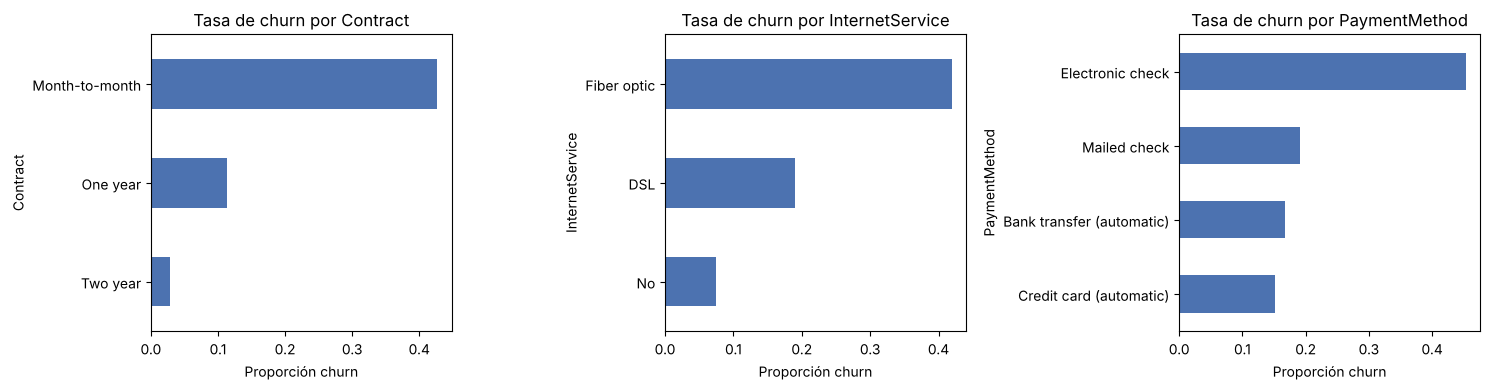

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    tasa_churn(col).sort_values().plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(f"Tasa de churn por {col}"); ax.set_xlabel("Proporción churn")
plt.tight_layout(); plt.show()

**Lectura:**
- Desbalance moderado (~26,5% churn): *accuracy* sola es engañosa (decir siempre "No" da 73,5%). Se usan **ROC-AUC** y **recall/F1 de la clase churn**.
- Mayor churn en contrato mes a mes, fibra óptica, cheque electrónico, poca antigüedad y sin soporte/seguridad.
- `gender` no muestra diferencia (≈26,9% vs 26,2%): no aporta señal y es atributo sensible → se excluye.
- Son asociaciones, no causalidad.

## 4. Variables del modelo
- **Excluidas:** `customerID` (identificador), `TotalCharges` (redundante), `gender` (sin señal, sensible).
- **Numéricas (3):** `tenure`, `MonthlyCharges`, `SeniorCitizen`.
- **Categóricas (14):** servicios, contrato, facturación y pago.
- Todas son conocidas para un cliente activo en el momento de la predicción (sin fuga de información).

## 5. Entrenamiento reproducible
`train.py` compara 3 modelos con CV estratificada (solo train), elige umbral sin tocar test, evalúa una vez en test y guarda `model.joblib`.

In [7]:
import subprocess, sys
print(subprocess.run([sys.executable, "train.py"], capture_output=True, text=True).stdout)

Tasa de churn por género (justifica excluirlo): {'Female': 0.269, 'Male': 0.262}
Train: (5634, 17) | Test: (1409, 17) | churn train=0.265

1) Comparación de modelos (CV estratificada 5 folds, solo train):
  logistic_regression      ROC-AUC CV=0.8452 (±0.0121) | train=0.8482 | recall CV=0.538
  random_forest            ROC-AUC CV=0.8431 (±0.0083) | train=0.9238 | recall CV=0.499
  hist_gradient_boosting   ROC-AUC CV=0.8418 (±0.0087) | train=0.9232 | recall CV=0.525

2) Modelo seleccionado: logistic_regression
3) Umbral elegido (max F1 out-of-fold): 0.325

4) Evaluación final en test:
{
  "threshold": 0.3251,
  "roc_auc": 0.8394,
  "recall_churn": 0.7139,
  "precision_churn": 0.5361,
  "f1_churn": 0.6124,
  "f1_weighted": 0.7695,
  "brier": 0.1391,
  "prob_media_predicha": 0.2678,
  "tasa_real": 0.2654,
  "accuracy": 0.7601,
  "confusion_matrix": [
    [
      804,
      231
    ],
    [
      107,
      267
    ]
  ]
}
              precision    recall  f1-score   support

    No churn 

In [8]:
cv = pd.read_csv("reports/cv_results.csv")
cv[["modelo", "cv_roc_auc_mean", "cv_roc_auc_std", "train_roc_auc_mean",
    "cv_recall_mean", "cv_f1_mean"]]

,modelo,cv_roc_auc_mean,cv_roc_auc_std,train_roc_auc_mean,cv_recall_mean,cv_f1_mean
0,logistic_regression,0.8452,0.0121,0.8482,0.5385,0.5894
1,random_forest,0.8431,0.0083,0.9238,0.4990,0.5728
2,hist_gradient_boosting,0.8418,0.0087,0.9232,0.5251,0.5831


**Selección:** la regresión logística tiene el mayor ROC-AUC en CV y casi no hay brecha train/CV.
Random Forest y Gradient Boosting alcanzan ~0,92 en train pero no mejoran en CV (sobreajuste sin ganancia).
Las diferencias de CV son menores que la desviación entre folds, así que se prefiere el modelo más simple e interpretable.

In [9]:
import json
print(json.dumps(json.load(open("reports/metrics.json")), indent=2, ensure_ascii=False))
pd.read_csv("reports/importancias.csv").head(8)

{
  "modelo_seleccionado": "logistic_regression",
  "regla_seleccion": "Mayor ROC-AUC CV; logística si queda a <= 0.01 del mejor",
  "test_umbral_elegido": {
    "threshold": 0.3251,
    "roc_auc": 0.8394,
    "recall_churn": 0.7139,
    "precision_churn": 0.5361,
    "f1_churn": 0.6124,
    "f1_weighted": 0.7695,
    "brier": 0.1391,
    "prob_media_predicha": 0.2678,
    "tasa_real": 0.2654,
    "accuracy": 0.7601,
    "confusion_matrix": [
      [
        804,
        231
      ],
      [
        107,
        267
      ]
    ]
  },
  "test_umbral_0_5": {
    "threshold": 0.5,
    "roc_auc": 0.8394,
    "recall_churn": 0.5535,
    "precision_churn": 0.6409,
    "f1_churn": 0.594,
    "f1_weighted": 0.7942,
    "brier": 0.1391,
    "prob_media_predicha": 0.2678,
    "tasa_real": 0.2654,
    "accuracy": 0.7991,
    "confusion_matrix": [
      [
        919,
        116
      ],
      [
        167,
        207
      ]
    ]
  },
  "n_train": 5634,
  "n_test": 1409,
  "tasa_churn": 0.26

,variable,importancia_auc,std
0,tenure,0.0831,0.0038
1,InternetService,0.0411,0.0080
2,Contract,0.0337,0.0041
3,MonthlyCharges,0.0249,0.0047
4,StreamingMovies,0.0043,0.0018
5,OnlineSecurity,0.0042,0.0014
6,StreamingTV,0.0039,0.0023
7,TechSupport,0.0034,0.0011


## 6. Probar el artefacto (como lo hará la app)

In [10]:
import joblib
art = joblib.load("model.joblib")
caso = pd.DataFrame([{
    "tenure": 2, "MonthlyCharges": 95.0, "SeniorCitizen": 1, "Partner": "No", "Dependents": "No",
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
    "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check"}], columns=art["features"])
p = art["model"].predict_proba(caso)[0, 1]
print(f"Probabilidad de churn: {p:.1%} -> {'Churn' if p >= art['threshold'] else 'No churn'} (umbral {art['threshold']:.2f})")

Probabilidad de churn: 77.8% -> Churn (umbral 0.33)


## 7. Probar Streamlit en Colab (túnel temporal)
La URL del túnel es solo para pruebas; el despliegue final es en la VM de GCP. localtunnel pide como contraseña la IP pública que imprime la celda.

In [11]:
if IN_COLAB:
    subprocess.Popen("streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1", shell=True)
    import time; time.sleep(5)
    print(open("streamlit.log").read())
    print("Contraseña del túnel:", subprocess.run(["curl", "-s", "https://loca.lt/mytunnelpassword"], capture_output=True, text=True).stdout)

In [12]:
# Ejecute solo en Colab; detenga la celda para cerrar el túnel.
# !npx --yes localtunnel --port 8501